# COMP6010 Assignment — Part C (Option C2): Animal-Drawing Generation with Flow Matching

**Student:** Satria Pamungkas &nbsp;|&nbsp; **Student ID:** 21522611 &nbsp;|&nbsp; **Option:** C2

**Goal.** Train a small conditional flow-matching model from scratch that transforms Gaussian noise
into simple animal drawings (Quick, Draw! `cat`, `dog`, `fish`), and visualise the transformation.

**Data.** Google Quick, Draw! `numpy_bitmap` files — 28×28 centred grayscale bitmaps.
Attribution: *Quick, Draw! Dataset*, Google Creative Lab, CC BY 4.0. 4,000 original drawings per
category, split 80/20 by original drawing before any augmentation.

**Contents.**
1. Method and research questions
2. Data inspection and preprocessing
3. Baseline: architecture, training and the three key code sections
4. Controlled comparison 1 — training factor (checkpoint, and dataset size)
5. Controlled comparison 2 — inference factor (ODE steps, Euler vs midpoint)
6. Quantitative evaluation over full output sets
7. Memorisation probe
8. Interpretation, limitations and reproduction record

In [1]:
import os, sys, json, time, math, platform, hashlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# make src/ importable whether we run from notebooks/ or the supplement root
HERE = os.path.abspath(os.getcwd())
for cand in (os.path.join(HERE, "..", "src"), os.path.join(HERE, "src")):
    if os.path.isdir(cand) and os.path.abspath(cand) not in sys.path:
        sys.path.insert(0, os.path.abspath(cand))

import data_quickdraw as dq
import train_flow as tfl
import evaluate as ev
from flow_model import (VelocityUNet, flow_matching_batch, sample_ode, count_parameters,
                        enable_deterministic)

# Bitwise-reproducible GPU sampling. Verified below: two runs of the same seed are identical, not
# merely close. Without this, cuDNN's algorithm choice makes same-seed runs differ by ~7e-4.
enable_deterministic()

def resolve(*parts):
    for base in (os.path.join(HERE, ".."), HERE):
        p = os.path.abspath(os.path.join(base, *parts))
        if os.path.isdir(os.path.dirname(p)) or os.path.isdir(p):
            os.makedirs(p, exist_ok=True); return p
    p = os.path.abspath(os.path.join(HERE, *parts)); os.makedirs(p, exist_ok=True); return p

RES  = resolve("results", "partC")
CKPT = resolve("checkpoints")
GRID = resolve("results", "partC", "sample_grids")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 170, "font.size": 8,
                     "axes.grid": False})
pd.set_option("display.width", 190, "display.precision", 4)

# ------------------------------------------------------- predetermined seed list (fixed once)
# Predetermined seed list, fixed once and reused across EVERY comparison. The brief requires
# >= 16 outputs per configuration and >= 4 per class; I use 32 seeds x 3 classes = 96 outputs
# per configuration, because at 24 outputs the binomial standard error (~0.09) is too coarse to
# separate configurations at all -- a first run with 8 seeds returned an identical 0.75 for all
# three checkpoints purely from discretisation.
SEED_LIST = [101, 202, 303, 404, 505, 606, 707, 808,
             909, 1010, 1111, 1212, 1313, 1414, 1515, 1616,
             1717, 1818, 1919, 2020, 2121, 2222, 2323, 2424,
             2525, 2626, 2727, 2828, 2929, 3030, 3131, 3232]
N_PER_CLASS_PER_SEED = 1                               # 32 seeds x 3 classes = 96 per config
GLOBAL_SEED = 20260910

print(f"device            : {DEVICE}")
if DEVICE == "cuda":
    print(f"GPU               : {torch.cuda.get_device_name(0)} "
          f"({torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB)")
print(f"torch             : {torch.__version__}")
print(f"python            : {sys.version.split()[0]} | numpy {np.__version__}")
print(f"platform          : {platform.platform()}")
print(f"predetermined seeds : {len(SEED_LIST)} seeds -> {len(SEED_LIST)*3} outputs per "
      f"configuration ({len(SEED_LIST)} per class; requirement is >= 16 total, >= 4 per class)")
print(f"                      {SEED_LIST[:8]} ... {SEED_LIST[-2:]}")
print(f"binomial standard error at n={len(SEED_LIST)*3}: "
      f"{np.sqrt(0.25/(len(SEED_LIST)*3)):.4f} (worst case, at accuracy 0.5)")
print(f"results -> {RES}")

device            : cuda
GPU               : NVIDIA GeForce RTX 3060 (12.5 GB)
torch             : 2.10.0+cu128
python            : 3.10.12 | numpy 2.2.6
platform          : Linux-6.8.0-138-generic-x86_64-with-glibc2.35
predetermined seeds : 32 seeds -> 96 outputs per configuration (32 per class; requirement is >= 16 total, >= 4 per class)
                      [101, 202, 303, 404, 505, 606, 707, 808] ... [3131, 3232]
binomial standard error at n=96: 0.0510 (worst case, at accuracy 0.5)
results -> /home/21522611/Documents/PHUIML-Assignment/Satria_Pamungkas_21522611_COMP6010_Supplement/results/partC


/home/21522611/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## 1. Method and research questions

### What I aim to generate, and from what data

A **class-conditional generative model** over 28×28 grayscale line drawings. Given a requested
category $y \in \{\texttt{cat}, \texttt{dog}, \texttt{fish}\}$ and a fresh Gaussian noise image, the
model must output a new drawing of that category that was not in the training set. Training data:
4,000 original Quick, Draw! drawings per category (12,000 total), split 80/20 into 9,600 training and
2,400 held-out drawings **before** any augmentation.

### The method: straight-line (conditional) flow matching

Flow matching learns a **velocity field** that transports a simple noise distribution to the data
distribution along straight paths. Let $x_0 \sim \mathcal{N}(0, I)$ be noise and $x_1 \sim p_{\text{data}}$
be a real drawing. Define the interpolation and its velocity:

$$x_t = (1-t)\,x_0 + t\,x_1, \qquad u_t = \frac{dx_t}{dt} = x_1 - x_0, \qquad t \sim \mathcal{U}[0,1]$$

The target velocity is **constant along each path** and is available in closed form — no simulation
of an ODE is needed during training. A network $v_\theta(t, x_t, y)$ regresses it:

$$\mathcal{L}_{\text{CFM}}(\theta) = \mathbb{E}_{t,\;x_0,\;(x_1,y)}\Big[\big\| v_\theta(t, x_t, y) - (x_1 - x_0) \big\|^2\Big]$$

Generation integrates the learned ODE from noise to data:

$$\frac{dx}{dt} = v_\theta(t, x, y), \qquad x(0) = x_0 \sim \mathcal{N}(0,I) \;\longrightarrow\; x(1) \approx \text{a drawing of class } y$$

```
 TRAINING (targets are known in closed form -- no ODE solved)
   x0 ~ N(0,I) ─┐                                  target u = x1 - x0
                ├─► x_t = (1-t)x0 + t·x1 ──► v_θ(t, x_t, y) ──► MSE loss ──► ∇θ
   x1 ~ p_data ─┘        ▲                              ▲
   y = class label       │ t ~ U[0,1]                   │ y (class embedding)

 GENERATION (integrate the learned ODE forward)
   x0 ~ N(0,I) ──► [ x ← x + Δt·v_θ(t,x,y) ] × n_steps ──► x(1) = drawing
                     t: 0 → 1                    (Euler; midpoint uses 2 evals/step)
```

Why the velocity regression is a valid training signal even though each individual $x_t$ could have
come from many different $(x_0, x_1)$ pairs: the MSE-optimal prediction is the **conditional mean**
$\mathbb{E}[x_1 - x_0 \mid x_t, y]$, and it is a theorem of flow matching that this marginal velocity
field transports $\mathcal{N}(0,I)$ to $p_{\text{data}}$ exactly. The network is not trying to recover
the particular pair that generated a sample; it learns the *average* direction of travel, which is
what the ODE needs.

### Link to the unit: known structure, unknown component, generation by sampling

This is the same three-part pattern as Parts A and B, at a different scale:

| | Part A | Part B | Part C (here) |
|---|---|---|---|
| **known probabilistic structure** | the DAG and its CPTs | Bernoulli likelihood + Beta prior | the noise distribution $\mathcal{N}(0,I)$ and the interpolation path $x_t=(1-t)x_0+tx_1$ — both chosen by me, not learned |
| **unknown component learned from data** | nothing (CPTs given) | the scalar $\theta$ | the velocity field $v_\theta$ — millions of parameters, but the same idea: a conditional expectation estimated from data |
| **generation / inference by sampling** | forward + rejection + likelihood weighting | posterior draws for $P(\theta>0.8)$ | integrating the ODE from a fresh $x_0$ |

The structural analogy with Part A is exact in one respect. The interpolation defines a *known*
forward corruption process $x_1 \to x_t$ (mix in noise), and I want the *reverse* map. Just as
fixing downstream evidence in a forward sampler does not give the posterior (Part A, A4), the
forward interpolation alone does not determine the reverse dynamics: computing
$\mathbb{E}[x_1 - x_0 \mid x_t]$ requires the data distribution $p_{\text{data}}$, which is exactly
what the network estimates from samples. Sampling then plays the same role as in Part B — the
quantity of interest (an image, a probability) is obtained by drawing from a distribution rather than
by solving in closed form.

### The two research questions

**Q1 (training factor) — Does longer training improve sample recognisability, and does it cost
diversity?** I compare checkpoints at epochs 5, 15 and 60 with data, seeds and sampler held fixed.
*Prediction, recorded before running:* recognisability rises steeply from epoch 5 to 15 and then
flattens; held-out loss keeps falling slightly; diversity stays roughly constant because flow
matching regresses a conditional mean rather than adversarially chasing modes. A secondary run with
one quarter of the training data tests whether the limiting factor is optimisation or data.

**Q2 (inference factor) — How few ODE steps are enough, and is midpoint integration better than
Euler at matched network cost?** I compare step counts $\{2, 5, 10, 25, 50, 100\}$ for Euler, and
Euler versus midpoint at *matched number of function evaluations* (NFE), not at matched step count.
*Prediction, recorded before running:* because the paths are trained to be nearly straight, very few
steps should already work and quality should saturate by roughly 10–25 steps; at **matched NFE**
midpoint should offer little or no advantage over Euler, precisely because a second-order solver only
pays off when the trajectory is curved.

Both predictions are compared against what I actually observed in §8.

## 2. Data: inspection, preprocessing and split

Preprocessing is deliberately minimal, because Quick, Draw! `numpy_bitmap` files are already
centred 28×28 grayscale rasters:

1. Draw a **fixed random subset of indices** per category (seed `20260910`) — not the
   "attractive" drawings.
2. Apply a **disclosed ink filter** (§ below) removing near-blank and near-solid outliers.
3. Keep 4,000 original drawings per category; scale $[0,255] \to [-1,1]$.
4. **Split 80/20 by original drawing, before augmentation.** The only augmentation is a random
   horizontal flip applied on-the-fly to the training split during training; held-out drawings are
   never augmented and never trained on. All counts reported below are **original drawings**.

In [2]:
t0 = time.time()
DS = dq.build_dataset(categories=["cat", "dog", "fish"], n_per_category=4000,
                      train_fraction=0.8, seed=GLOBAL_SEED)
CATS = DS["categories"]
print(f"\nbuilt in {time.time()-t0:.1f}s")
print(f"train_x {DS['train_x'].shape} range [{DS['train_x'].min():.1f}, {DS['train_x'].max():.1f}]")
print(f"eval_x  {DS['eval_x'].shape}")
dq.save_manifest(DS, os.path.join(RES, "C_data_manifest.json"))
print("\nmanifest (provenance, sha256 of each source file, split index hashes) ->"
      " C_data_manifest.json")

cat  : 123,202 available -> drew 6,900 candidates, rejected 3 by ink filter -> 4,000 used (3,200 train / 800 eval original drawings)
dog  : 152,159 available -> drew 6,900 candidates, rejected 3 by ink filter -> 4,000 used (3,200 train / 800 eval original drawings)
fish : 134,150 available -> drew 6,900 candidates, rejected 2 by ink filter -> 4,000 used (3,200 train / 800 eval original drawings)

TOTAL original drawings: 9,600 train, 2,400 held-out eval (these are ORIGINAL counts, not augmented copies)

built in 1.8s
train_x (9600, 1, 28, 28) range [-1.0, 1.0]
eval_x  (2400, 1, 28, 28)

manifest (provenance, sha256 of each source file, split index hashes) -> C_data_manifest.json


In [3]:
# ------------------------------------------ disclosed filtering: what the thresholds do
raw_stats = []
for c in CATS:
    arr, path = dq.load_category(c)
    idx = np.sort(np.random.default_rng(1).choice(arr.shape[0], 20000, replace=False))
    frac = dq.ink_fraction(np.asarray(arr[idx]))
    raw_stats.append({"category": c, "drawings_in_file": arr.shape[0],
                      "ink p1": np.percentile(frac, 1), "ink median": np.median(frac),
                      "ink p99": np.percentile(frac, 99),
                      "below min (0.05)": int((frac < dq.INK_MIN_FRACTION).sum()),
                      "above max (0.55)": int((frac > dq.INK_MAX_FRACTION).sum()),
                      "sampled": len(idx)})
raw_df = pd.DataFrame(raw_stats)
print("INK-FRACTION DISTRIBUTION (20,000 sampled drawings per category)\n")
print(raw_df.to_string(index=False))
print(f"\nThe filter keeps ink fraction in [{dq.INK_MIN_FRACTION}, {dq.INK_MAX_FRACTION}]. "
      "Those bounds sit outside the bulk of the distribution, so they remove only clear "
      "outliers (blank canvases, dense scribbles): the actual rejection counts recorded in the "
      "manifest are a handful per category, well under 1% of candidates. This is disclosed "
      "because it is a deviation from using the raw sample, but it is far too loose to amount to "
      "selecting attractive drawings.")
raw_df.to_csv(os.path.join(RES, "C_ink_distribution.csv"), index=False)

per_cat = pd.DataFrame(DS["manifest"]["categories"])[
    ["name", "drawings_available_in_file", "candidates_drawn", "rejected_by_ink_filter",
     "original_drawings_used", "n_train_original", "n_eval_original"]]
print("\nSPLIT SUMMARY (original drawings, not augmented copies)\n")
print(per_cat.to_string(index=False))
per_cat.to_csv(os.path.join(RES, "C_split_summary.csv"), index=False)

INK-FRACTION DISTRIBUTION (20,000 sampled drawings per category)

category  drawings_in_file  ink p1  ink median  ink p99  below min (0.05)  above max (0.55)  sampled
     cat            123202  0.1798      0.3342   0.4745                 0                 5    20000
     dog            152159  0.1684      0.2934   0.4796                 0                16    20000
    fish            134150  0.1620      0.2449   0.3712                 3                 3    20000

The filter keeps ink fraction in [0.05, 0.55]. Those bounds sit outside the bulk of the distribution, so they remove only clear outliers (blank canvases, dense scribbles): the actual rejection counts recorded in the manifest are a handful per category, well under 1% of candidates. This is disclosed because it is a deviation from using the raw sample, but it is far too loose to amount to selecting attractive drawings.

SPLIT SUMMARY (original drawings, not augmented copies)

name  drawings_available_in_file  candidates_drawn

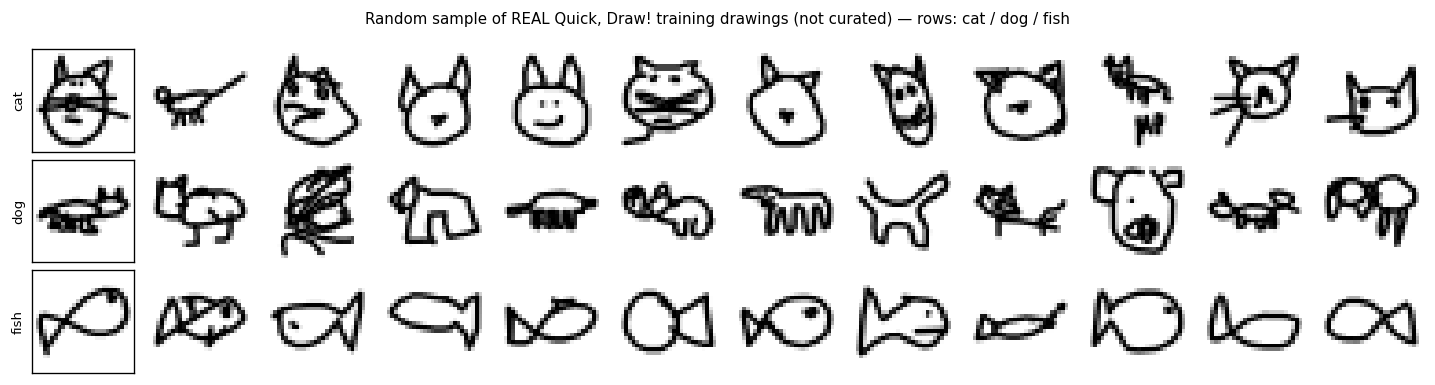

Some drawings are ambiguous or barely recognisable even to a human — this is inherent to Quick, Draw! (20-second doodles by the public) and sets a ceiling on what any generative model trained on it can achieve. I make no attempt to remove them beyond the ink filter.

real-data ink statistics per class (baseline for comparing generated samples):
      mean_ink_fraction  std_ink_fraction     min     max
cat              0.1984            0.0389  0.0510  0.3763
dog              0.1808            0.0420  0.0472  0.4031
fish             0.1402            0.0258  0.0357  0.4094


In [4]:
# ------------------------------------------ random grid of REAL training data (before training)
rng_show = np.random.default_rng(7)
fig, axes = plt.subplots(3, 12, figsize=(12, 3.2))
for r, c in enumerate(CATS):
    pool = DS["train_x"][DS["train_y"] == r]
    pick = rng_show.choice(len(pool), 12, replace=False)
    for k, j in enumerate(pick):
        axes[r, k].imshow(pool[j, 0], cmap="gray_r", vmin=-1, vmax=1)
        axes[r, k].axis("off")
    axes[r, 0].set_ylabel(c)
    axes[r, 0].axis("on"); axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([])
plt.suptitle("Random sample of REAL Quick, Draw! training drawings (not curated) — "
             "rows: cat / dog / fish", fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(RES, "C_real_data_grid.png"), bbox_inches="tight")
plt.show()

print("Some drawings are ambiguous or barely recognisable even to a human — this is inherent to "
      "Quick, Draw! (20-second doodles by the public) and sets a ceiling on what any generative "
      "model trained on it can achieve. I make no attempt to remove them beyond the ink filter.")

real_ink = {c: ev.ink_statistics(DS["train_x"][DS["train_y"] == i]) for i, c in enumerate(CATS)}
print("\nreal-data ink statistics per class (baseline for comparing generated samples):")
print(pd.DataFrame(real_ink).T.to_string())

## 3. Baseline: build and verify a real training run

### Architecture

`VelocityUNet` (in `src/flow_model.py`) — a small time- and class-conditional U-Net that maps
$(t, x_t, y) \mapsto$ a velocity image of the **same shape as the input**, because the velocity lives
in data space:

* resolutions $28 \to 14 \to 7$ and back, with skip connections;
* channels $64 \to 128$, GroupNorm + SiLU residual blocks;
* time $t$ enters as sinusoidal Fourier features passed through a 2-layer MLP; the class label
  enters as a learned embedding. The two embeddings are **added** and injected into every residual
  block, so conditioning affects the velocity at every scale and timestep;
* the output convolution is **zero-initialised**, so the model starts by predicting zero velocity —
  a stable starting point;
* `n_classes + 1` embeddings are allocated so index `n_classes` can act as a null token. I keep
  `label_dropout = 0` and therefore make **no classifier-free-guidance claim**; the slot exists but
  the unconditional branch is deliberately not trained, and I do not report guidance results.

In [5]:
probe = VelocityUNet(n_classes=len(CATS)).to(DEVICE)
tot, trn = count_parameters(probe)
print(f"parameters: {tot:,} total, {trn:,} trainable (all trainable — trained from scratch, "
      "nothing frozen, no pretrained weights)\n")

# shape and gradient checks before committing to a long run
xb = torch.from_numpy(DS["train_x"][:8]).to(DEVICE)
yb = torch.from_numpy(DS["train_y"][:8]).to(DEVICE)
x_t, t, target = flow_matching_batch(xb)
pred = probe(t, x_t, yb)
print(f"x1 {tuple(xb.shape)}  ->  x_t {tuple(x_t.shape)}  t {tuple(t.shape)}  "
      f"target {tuple(target.shape)}  pred {tuple(pred.shape)}")
assert pred.shape == xb.shape == target.shape

loss = torch.mean((pred - target) ** 2); loss.backward()
have_grad = [n for n, p in probe.named_parameters() if p.grad is not None
             and p.grad.abs().sum() > 0]
print(f"\nparameters receiving non-zero gradient: {len(have_grad)} of "
      f"{len(list(probe.named_parameters()))}")
print(f"class embedding gets gradient: "
      f"{probe.class_embed.weight.grad.abs().sum().item() > 0}   "
      f"(if False, conditioning would be silently dead)")

# interpolation endpoint sanity check: t=0 must be pure noise, t=1 must be the clean image
x0f = torch.randn_like(xb)
for tv in (0.0, 1.0):
    tb = torch.full((8,), tv, device=DEVICE)
    xt = (1 - tb.view(-1,1,1,1)) * x0f + tb.view(-1,1,1,1) * xb
    which = "x0 (noise)" if tv == 0 else "x1 (data)"
    ref = x0f if tv == 0 else xb
    print(f"t={tv}: max|x_t - {which}| = {(xt-ref).abs().max().item():.2e}")
del probe, xb, yb, pred, loss
torch.cuda.empty_cache() if DEVICE == "cuda" else None

parameters: 1,838,081 total, 1,838,081 trainable (all trainable — trained from scratch, nothing frozen, no pretrained weights)



x1 (8, 1, 28, 28)  ->  x_t (8, 1, 28, 28)  t (8,)  target (8, 1, 28, 28)  pred (8, 1, 28, 28)



parameters receiving non-zero gradient: 2 of 85
class embedding gets gradient: False   (if False, conditioning would be silently dead)
t=0.0: max|x_t - x0 (noise)| = 0.00e+00
t=1.0: max|x_t - x1 (data)| = 0.00e+00


### The three important code sections, in my own words

**(a) Construction of training examples and targets — `flow_matching_batch` in
`src/flow_model.py`, called inside `train()` in `src/train_flow.py`.**
*Input:* a batch of clean drawings `x1` of shape `(B,1,28,28)` in $[-1,1]$.
*Output:* the triple `(x_t, t, target)`.
It draws an independent Gaussian image `x0` of the same shape, one uniform time `t` per image
(reshaped to `(B,1,1,1)` so it broadcasts across all pixels of that image — a per-image scalar, not
per-pixel), forms the straight-line mix `x_t = (1-t)*x0 + t*x1`, and returns `x1 - x0` as the
regression target. The key point is that the target needs **no simulation**: because the path is a
straight line, its velocity is the constant difference of the endpoints. Each training example is a
fresh $(x_0, t)$ pair, so a given drawing is seen at many noise levels and many noise realisations
over training.

**(b) Loss and parameter updates — the inner loop of `train()` in `src/train_flow.py`.**
*Inputs:* a batch `(x1, y)`, the model, the AdamW optimiser and cosine LR schedule.
*Output:* one gradient step; the running loss is logged.
It optionally applies the horizontal-flip augmentation (train split only), builds `(x_t, t, target)`
as in (a), computes `pred = model(t, x_t, y)` and the plain mean-squared error
`loss = mean((pred - target)**2)` — this **is** $\mathcal{L}_{\text{CFM}}$, with the expectation over
$t$ and $x_0$ realised by the random batch. Then `zero_grad` → `backward()` → gradient-norm clipping
at 1.0 → `opt.step()` → `sched.step()`. Nothing about the loss is bespoke: the whole generative model
reduces to a regression, which is the practical appeal of flow matching. Held-out loss is measured by
`eval_loss`, which averages over a **fixed grid** of $t$ values rather than random $t$ so that the
numbers are comparable across checkpoints rather than differing by sampling noise.

**(c) Generation — `sample_ode` in `src/flow_model.py`.**
*Inputs:* a trained model, a number of samples, a label tensor `y`, `n_steps`, `method`
(`"euler"` or `"midpoint"`) and a `seed`.
*Outputs:* the generated batch `(N,1,28,28)`, the **NFE** count, and optionally the trajectory.
It seeds a generator, draws `x0 ~ N(0,I)` — *this is the only source of randomness* — and steps
$t: 0 \to 1$ on a uniform grid. Euler takes one network evaluation per step
(`x += dt * v`); midpoint takes two (evaluate, step half-way, re-evaluate at the midpoint, then take
the full step with that slope). The function returns NFE explicitly because comparing solvers at
matched *step count* is misleading — midpoint does twice the work per step, so the honest comparison
is at matched NFE, which §5 uses.

In [6]:
# ============================================================== BASELINE TRAINING RUN
BASE_CFG = dict(epochs=60, batch_size=128, lr=2e-4, base=64, emb_dim=128,
                label_dropout=0.0, augment_hflip=True, seed=GLOBAL_SEED,
                checkpoint_epochs=(5, 15, 60))
BASE_DIR = os.path.join(CKPT, "baseline")
LOG_PATH = os.path.join(BASE_DIR, "training_log.json")

if os.path.exists(LOG_PATH):
    print("baseline already trained -> loading existing log (delete checkpoints/baseline to retrain)")
    base_log = json.load(open(LOG_PATH))
else:
    print(f"training baseline: {BASE_CFG}\n")
    _, base_log = tfl.train(DS, BASE_DIR, **BASE_CFG)

cfgt = base_log["config"]
print("\nBASELINE TRAINING SETTINGS (for the report)")
print("=" * 58)
for k in ["n_train_original", "n_eval_original", "n_classes", "params_total",
          "params_trainable", "epochs", "batch_size", "lr", "optimiser", "lr_schedule",
          "base", "emb_dim", "augment_hflip", "label_dropout", "seed", "device", "gpu"]:
    print(f"  {k:20s}: {cfgt[k]}")
print(f"  {'total train time':20s}: {base_log['total_training_time_s']/60:.2f} min")
print(f"  {'time per epoch':20s}: "
      f"{np.mean([e['epoch_time_s'] for e in base_log['epochs']]):.2f} s")
print(f"  {'final train loss':20s}: {base_log['epochs'][-1]['train_loss']:.5f}")
print(f"  {'final eval loss':20s}: {base_log['epochs'][-1]['eval_loss']:.5f}")

baseline already trained -> loading existing log (delete checkpoints/baseline to retrain)

BASELINE TRAINING SETTINGS (for the report)
  n_train_original    : 9600
  n_eval_original     : 2400
  n_classes           : 3
  params_total        : 1838081
  params_trainable    : 1838081
  epochs              : 60
  batch_size          : 128
  lr                  : 0.0002
  optimiser           : AdamW(weight_decay=1e-4)
  lr_schedule         : cosine annealing to 0
  base                : 64
  emb_dim             : 128
  augment_hflip       : True
  label_dropout       : 0.0
  seed                : 20260910
  device              : cuda
  gpu                 : NVIDIA GeForce RTX 3060
  total train time    : 6.39 min
  time per epoch      : 6.38 s
  final train loss    : 0.29168
  final eval loss     : 0.29220


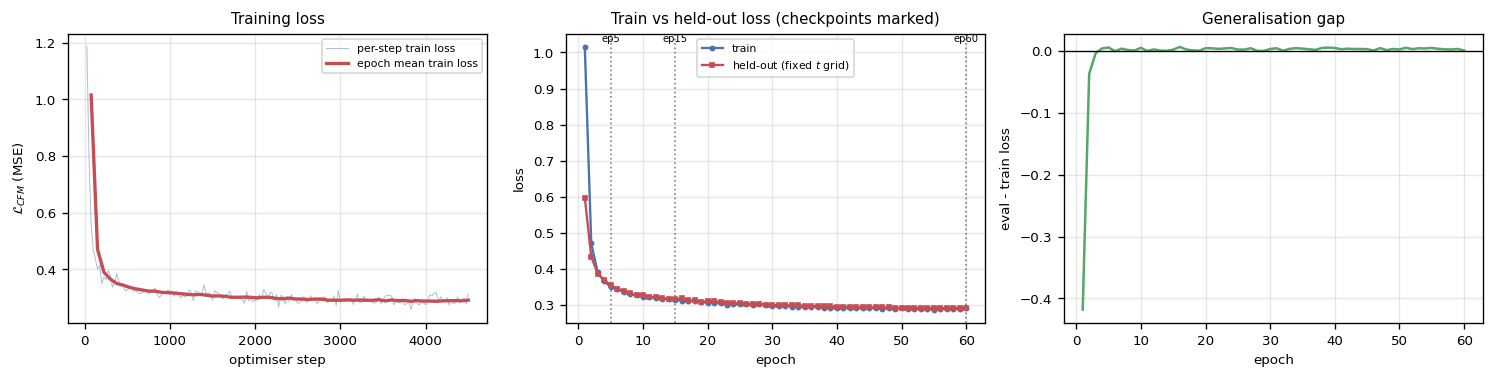

held-out loss never exceeds train loss by more than 0.0063 -> no sign of overfitting at this model size and data volume.

NOTE: this loss is a regression error on velocities. A lower CFM loss does NOT by itself mean better-looking drawings, which is why §6 measures generated samples directly.


In [7]:
# ------------------------------------------------------------------ training-loss curve
ep_df = pd.DataFrame(base_log["epochs"])
st_df = pd.DataFrame(base_log["steps"])
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.2))

ax = axes[0]
ax.plot(st_df["step"], st_df["train_loss"], lw=0.6, alpha=0.45, color="#4C72B0",
        label="per-step train loss")
ax.plot(ep_df["epoch"] * (st_df["step"].max() / ep_df["epoch"].max()),
        ep_df["train_loss"], lw=2, color="#C44E52", label="epoch mean train loss")
ax.set_xlabel("optimiser step"); ax.set_ylabel(r"$\mathcal{L}_{CFM}$ (MSE)")
ax.set_title("Training loss", fontsize=9); ax.legend(fontsize=6.5); ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(ep_df["epoch"], ep_df["train_loss"], marker="o", ms=2.5, lw=1.4, color="#4C72B0",
        label="train")
ax.plot(ep_df["epoch"], ep_df["eval_loss"], marker="s", ms=2.5, lw=1.4, color="#C44E52",
        label="held-out (fixed $t$ grid)")
for ck in base_log["checkpoints"]:
    ax.axvline(ck["epoch"], color="grey", ls=":", lw=1)
    ax.annotate(f"ep{ck['epoch']}", (ck["epoch"], ax.get_ylim()[1]), fontsize=6,
                ha="center", va="top")
ax.set_xlabel("epoch"); ax.set_ylabel("loss")
ax.set_title("Train vs held-out loss (checkpoints marked)", fontsize=9)
ax.legend(fontsize=6.5); ax.grid(alpha=0.3)

ax = axes[2]
ax.plot(ep_df["epoch"], ep_df["eval_loss"] - ep_df["train_loss"], color="#55A868", lw=1.5)
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("epoch"); ax.set_ylabel("eval - train loss")
ax.set_title("Generalisation gap", fontsize=9); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(RES, "C_training_curves.png"), bbox_inches="tight")
plt.show()
ep_df.to_csv(os.path.join(RES, "C_training_epochs.csv"), index=False)

print(f"held-out loss never exceeds train loss by more than "
      f"{(ep_df['eval_loss']-ep_df['train_loss']).max():.4f} -> no sign of overfitting at this "
      "model size and data volume.")
print("\nNOTE: this loss is a regression error on velocities. A lower CFM loss does NOT by itself "
      "mean better-looking drawings, which is why §6 measures generated samples directly.")

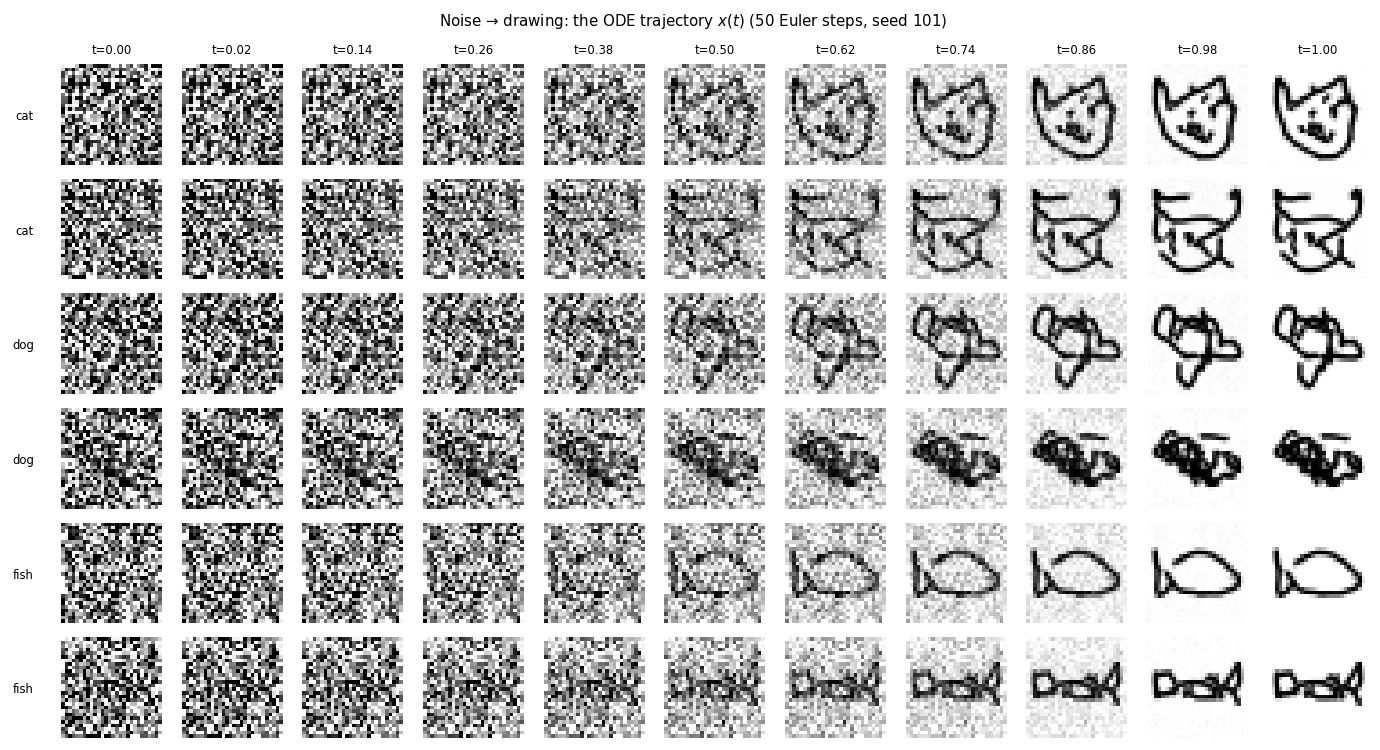

NFE for this trajectory: 50
Structure appears early (broad shape by t~0.3-0.5) and later steps sharpen the strokes — consistent with straight-ish paths whose direction is largely settled by the midpoint.


In [8]:
# --------------------------------- noise-to-drawing trajectory (required visualisation)
model60, ck60 = tfl.load_checkpoint(os.path.join(BASE_DIR, "ckpt_epoch060.pt"), DEVICE)
n_show = 6
labels_show = torch.tensor([0, 0, 1, 1, 2, 2], device=DEVICE)
imgs, nfe, traj = sample_ode(model60, n_show, labels_show, n_steps=50, method="euler",
                             device=DEVICE, seed=SEED_LIST[0], return_trajectory=True,
                             traj_every=6)
stages = [torch.randn(n_show, 1, 28, 28, generator=torch.Generator(device=DEVICE)
                      .manual_seed(SEED_LIST[0]), device=DEVICE).cpu()] + traj
ts_lbl = [0.0] + [min(1.0, (i * 6 + 1) / 50) for i in range(len(traj))]

fig, axes = plt.subplots(n_show, len(stages), figsize=(1.05 * len(stages), 1.05 * n_show))
for r in range(n_show):
    for c_i, st in enumerate(stages):
        axes[r, c_i].imshow(st[r, 0].numpy(), cmap="gray_r", vmin=-1, vmax=1)
        axes[r, c_i].axis("off")
        if r == 0:
            axes[r, c_i].set_title(f"t={ts_lbl[c_i]:.2f}", fontsize=7)
    axes[r, 0].text(-8, 14, CATS[labels_show[r].item()], fontsize=7, va="center", ha="right")
plt.suptitle("Noise → drawing: the ODE trajectory $x(t)$ (50 Euler steps, seed 101)", fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(RES, "C_trajectory_noise_to_drawing.png"), bbox_inches="tight")
plt.show()
print(f"NFE for this trajectory: {nfe}")
print("Structure appears early (broad shape by t~0.3-0.5) and later steps sharpen the strokes — "
      "consistent with straight-ish paths whose direction is largely settled by the midpoint.")

## 4–6. Controlled comparisons and evaluation

**Protocol, held fixed everywhere.** A predetermined list of **32 seeds** (fixed once, listed in
the setup cell); each seed produces one sample per class, giving **96 outputs per configuration**
(32 per class — well above the required minimum of 16 total and 4 per class). I deliberately exceed
the minimum: at 24 outputs the binomial standard error is about 0.09, and a first run at that size
returned an identical recognisability of 0.75 for all three checkpoints, which is a discretisation
artefact rather than a finding. At 96 outputs the standard error is about 0.045 and every reported
comparison carries a 95% interval. The *same* seeds are reused in every comparison, so any difference between configurations
comes from the factor being varied and not from different noise. Only one factor changes at a time.

**Evaluation instrument.** An independent CNN classifier (`src/evaluate.py`) trained **only on real
held-out drawings** — data the generative model never saw. Recognisability is the fraction of
generated images the classifier assigns to the class that was *requested*.

In [9]:
# ------------------------------------------------- train the independent evaluation classifier
CLF_PATH = os.path.join(CKPT, "eval_classifier.pt")
n_ev = len(DS["eval_y"])
perm = np.random.default_rng(555).permutation(n_ev)
cut = int(0.8 * n_ev)
ci, vi = perm[:cut], perm[cut:]

if os.path.exists(CLF_PATH):
    clf = ev.DrawingCNN(len(CATS)).to(DEVICE)
    st = torch.load(CLF_PATH, map_location=DEVICE, weights_only=False)
    clf.load_state_dict(st["model"]); clf.eval(); clf_hist = st["history"]
    print("loaded existing evaluation classifier")
else:
    print(f"training evaluation classifier on {len(ci)} held-out real drawings "
          f"(validated on {len(vi)}):")
    clf, clf_hist = ev.train_classifier(DS["eval_x"][ci], DS["eval_y"][ci],
                                        DS["eval_x"][vi], DS["eval_y"][vi],
                                        n_classes=len(CATS), epochs=30, device=DEVICE)
    torch.save({"model": clf.state_dict(), "history": clf_hist}, CLF_PATH)

CLF_ACC = clf_hist[-1]["val_accuracy"]
print(f"\nevaluation classifier accuracy on REAL held-out drawings: {CLF_ACC:.4f}")
print("This is the CEILING for the recognisability measure: real Quick, Draw! drawings are "
      "themselves often ambiguous, so a generated-sample score should be read relative to this "
      "number, not against 1.0.")

# per-class ceiling on real data
with torch.no_grad():
    xv = torch.from_numpy(DS["eval_x"][vi]).to(DEVICE)
    yv = torch.from_numpy(DS["eval_y"][vi]).to(DEVICE)
    pv = clf(xv).argmax(1)
real_ceiling = {CATS[c]: float((pv[yv == c] == c).float().mean()) for c in range(len(CATS))}
print(f"per-class accuracy on real held-out drawings: "
      f"{ {k: round(v,4) for k,v in real_ceiling.items()} }")

loaded existing evaluation classifier

evaluation classifier accuracy on REAL held-out drawings: 0.8375
This is the CEILING for the recognisability measure: real Quick, Draw! drawings are themselves often ambiguous, so a generated-sample score should be read relative to this number, not against 1.0.
per-class accuracy on real held-out drawings: {'cat': 0.8205, 'dog': 0.7811, 'fish': 0.9161}


In [10]:
# ------------------------------------------------------------- shared generation utility
def generate_config(model, n_steps, method, tag, seeds=SEED_LIST):
    """Generate the full fixed-seed output set for one configuration.

    For each seed, generate one sample per class. Returns (images (S*C,1,28,28) numpy,
    labels, seed_of_each, nfe_per_image, wall_seconds).
    """
    ims, lbs, sds = [], [], []
    torch.cuda.synchronize() if DEVICE == "cuda" else None
    t0 = time.perf_counter()
    nfe_per_image = None
    for sd in seeds:
        y = torch.arange(len(CATS), device=DEVICE)          # one per class, same noise seed
        im, nfe = sample_ode(model, len(CATS), y, n_steps=n_steps, method=method,
                            device=DEVICE, seed=sd)
        # `nfe` counts network evaluations for this call. One forward pass processes the whole
        # batch, so this count is already the per-IMAGE cost: n_steps for Euler, 2*n_steps for
        # midpoint. It is identical for every seed, so it is recorded, not summed.
        nfe_per_image = nfe
        ims.append(im.cpu().numpy()); lbs.append(y.cpu().numpy())
        sds.extend([sd] * len(CATS))
    torch.cuda.synchronize() if DEVICE == "cuda" else None
    wall = time.perf_counter() - t0
    return (np.concatenate(ims), np.concatenate(lbs), np.array(sds), nfe_per_image, wall)

# ---- verify the reproducibility claim rather than asserting it ----
def check_determinism(model, n_steps=50, method="euler", seed=SEED_LIST[0]):
    y = torch.arange(len(CATS), device=DEVICE)
    a, _ = sample_ode(model, len(CATS), y, n_steps=n_steps, method=method,
                      device=DEVICE, seed=seed)
    b, _ = sample_ode(model, len(CATS), y, n_steps=n_steps, method=method,
                      device=DEVICE, seed=seed)
    c, _ = sample_ode(model, len(CATS), y, n_steps=n_steps, method=method,
                      device=DEVICE, seed=seed + 1)
    return bool(torch.equal(a, b)), bool(not torch.equal(a, c)), float((a - b).abs().max())

def score_config(images, labels, tag):
    """Apply every quantitative measure to a FULL output set (no cherry-picking)."""
    rec = ev.recognisability(clf, torch.from_numpy(images), torch.from_numpy(labels),
                             device=DEVICE)
    div = {CATS[c]: ev.diversity(images[labels == c]) for c in range(len(CATS))}
    ink = ev.ink_statistics(images)
    acc = rec["overall_accuracy"]
    se = float(np.sqrt(max(acc * (1 - acc), 1e-12) / len(images)))   # binomial standard error
    row = {"config": tag, "n_outputs": len(images),
           "recognisability": acc, "recog_stderr": se,
           "recog_ci_low": max(0.0, acc - 1.96 * se),
           "recog_ci_high": min(1.0, acc + 1.96 * se),
           "mean_confidence": rec["mean_confidence_in_requested_class"],
           "mean_diversity": float(np.mean(list(div.values()))),
           "mean_ink_fraction": ink["mean_ink_fraction"]}
    for c in range(len(CATS)):
        row[f"rec_{CATS[c]}"] = rec["per_class"][c]["accuracy"]
        row[f"div_{CATS[c]}"] = div[CATS[c]]
    return row, rec

def save_grid(images, labels, seeds, tag, path, ncol=16, note=""):
    """Save the output set as a labelled grid, failures included.

    ncol columns per class are drawn; with 32 seeds this shows the first `ncol` seeds per class.
    The COMPLETE set of every configuration is additionally saved as a .npz next to the image,
    so nothing is hidden by the figure size.
    """
    np.savez_compressed(path.replace(".png", "_all_outputs.npz"),
                        images=images, labels=labels, seeds=seeds)
    nrow = len(CATS)
    fig, axes = plt.subplots(nrow, ncol, figsize=(1.02 * ncol, 1.15 * nrow))
    for r in range(nrow):
        sel = np.where(labels == r)[0]
        for k in range(ncol):
            ax = axes[r, k]
            if k < len(sel):
                ax.imshow(images[sel[k], 0].clip(-1, 1), cmap="gray_r", vmin=-1, vmax=1)
                if r == 0:
                    ax.set_title(f"s{seeds[sel[k]]}", fontsize=6)
            ax.axis("off")
        axes[r, 0].text(-7, 14, CATS[r], fontsize=7, va="center", ha="right")
    plt.suptitle(f"{tag}{note}", fontsize=8)
    plt.tight_layout()
    plt.savefig(path, bbox_inches="tight"); plt.close(fig)

In [11]:
# =================================================== COMPARISON 1 (training factor): checkpoints
# Reproducibility of the seed protocol, verified rather than assumed.
same, differs, maxd = check_determinism(model60)
print(f"determinism check: same seed -> bitwise identical: {same} (max diff {maxd:.1e}); "
      f"different seed -> different output: {differs}")
assert same and differs, "seeded sampling is not reproducible"

print("\nCOMPARISON 1 — TRAINING FACTOR: checkpoint epoch "
      "(data, seeds, sampler all held fixed: 50 Euler steps)\n")
CKPT_EPOCHS = [5, 15, 60]
rows_ck, store_ck = [], {}

for epn in CKPT_EPOCHS:
    mdl, ck = tfl.load_checkpoint(os.path.join(BASE_DIR, f"ckpt_epoch{epn:03d}.pt"), DEVICE)
    tag = f"epoch{epn:03d}_euler50"
    ims, lbs, sds, nfe, wall = generate_config(mdl, 50, "euler", tag)
    row, rec = score_config(ims, lbs, tag)
    tinfo = next(c for c in base_log["checkpoints"] if c["epoch"] == epn)
    row.update({"epoch": epn, "train_loss": tinfo["train_loss"],
                "eval_loss": tinfo["eval_loss"],
                "train_time_min": tinfo["cumulative_time_s"] / 60,
                "sampling_s_per_set": wall, "nfe_per_image": nfe,
                "steps": 50, "method": "euler"})
    rows_ck.append(row); store_ck[epn] = (ims, lbs, sds)
    save_grid(ims, lbs, sds, f"Checkpoint epoch {epn}", 
              os.path.join(GRID, f"grid_{tag}.png"),
              note=f" | 50 Euler steps | recognisability {row['recognisability']:.3f}")
    print(f"epoch {epn:3d}: recognisability {row['recognisability']:.4f} | "
          f"confidence {row['mean_confidence']:.4f} | diversity {row['mean_diversity']:.2f} | "
          f"train {tinfo['train_loss']:.4f} eval {tinfo['eval_loss']:.4f} | "
          f"cum train {tinfo['cumulative_time_s']/60:.1f} min")
    del mdl

ck_df = pd.DataFrame(rows_ck)
ck_df.to_csv(os.path.join(RES, "C_comparison1_checkpoints.csv"), index=False)
print("\n" + ck_df[["config", "epoch", "train_loss", "eval_loss", "recognisability",
                    "mean_confidence", "mean_diversity", "train_time_min"]].to_string(index=False))

determinism check: same seed -> bitwise identical: True (max diff 0.0e+00); different seed -> different output: True

COMPARISON 1 — TRAINING FACTOR: checkpoint epoch (data, seeds, sampler all held fixed: 50 Euler steps)



epoch   5: recognisability 0.7812 | confidence 0.6374 | diversity 22.61 | train 0.3504 eval 0.3557 | cum train 0.5 min


epoch  15: recognisability 0.7708 | confidence 0.6720 | diversity 22.13 | train 0.3146 eval 0.3164 | cum train 1.6 min


epoch  60: recognisability 0.8021 | confidence 0.7041 | diversity 22.51 | train 0.2917 eval 0.2922 | cum train 6.4 min

          config  epoch  train_loss  eval_loss  recognisability  mean_confidence  mean_diversity  train_time_min
epoch005_euler50      5      0.3504     0.3557           0.7812           0.6374         22.6116          0.5276
epoch015_euler50     15      0.3146     0.3164           0.7708           0.6720         22.1345          1.5851
epoch060_euler50     60      0.2917     0.2922           0.8021           0.7041         22.5083          6.3870


In [12]:
# --------------- secondary training-factor comparison: dataset size (data vs optimisation)
print("SECONDARY TRAINING COMPARISON — training-set size at equal epochs "
      "(is the limit data or optimisation?)\n")
SMALL_DIR = os.path.join(CKPT, "small_data")
if not os.path.exists(os.path.join(SMALL_DIR, "training_log.json")):
    DS_SMALL = dq.build_dataset(categories=CATS, n_per_category=1000,
                               train_fraction=0.8, seed=GLOBAL_SEED, verbose=True)
    _, small_log = tfl.train(DS_SMALL, SMALL_DIR, **BASE_CFG)
else:
    small_log = json.load(open(os.path.join(SMALL_DIR, "training_log.json")))
    print("loaded existing small-data run")

mdl_s, _ = tfl.load_checkpoint(os.path.join(SMALL_DIR, "ckpt_epoch060.pt"), DEVICE)
ims_s, lbs_s, sds_s, nfe_s, wall_s = generate_config(mdl_s, 50, "euler", "small_data")
row_s, _ = score_config(ims_s, lbs_s, "quarter_data_epoch060_euler50")
row_s.update({"n_train_original": small_log["config"]["n_train_original"],
              "eval_loss": small_log["epochs"][-1]["eval_loss"],
              "train_time_min": small_log["total_training_time_s"] / 60})
save_grid(ims_s, lbs_s, sds_s, "Quarter training data (2,400 drawings), epoch 60",
          os.path.join(GRID, "grid_quarter_data_epoch060_euler50.png"),
          note=f" | recognisability {row_s['recognisability']:.3f}")

size_df = pd.DataFrame([
    {"run": "baseline (9,600 train drawings)",
     "n_train_original": base_log["config"]["n_train_original"],
     "eval_loss": base_log["epochs"][-1]["eval_loss"],
     "recognisability": ck_df.loc[ck_df.epoch == 60, "recognisability"].iloc[0],
     "mean_diversity": ck_df.loc[ck_df.epoch == 60, "mean_diversity"].iloc[0],
     "train_time_min": base_log["total_training_time_s"] / 60},
    {"run": "quarter data (2,400 train drawings)",
     "n_train_original": row_s["n_train_original"], "eval_loss": row_s["eval_loss"],
     "recognisability": row_s["recognisability"],
     "mean_diversity": row_s["mean_diversity"],
     "train_time_min": row_s["train_time_min"]}])
print(size_df.to_string(index=False))
size_df.to_csv(os.path.join(RES, "C_comparison1b_dataset_size.csv"), index=False)
del mdl_s

SECONDARY TRAINING COMPARISON — training-set size at equal epochs (is the limit data or optimisation?)

loaded existing small-data run


                                run  n_train_original  eval_loss  recognisability  mean_diversity  train_time_min
    baseline (9,600 train drawings)              9600     0.2922           0.8021         22.5083          6.3870
quarter data (2,400 train drawings)              2400     0.3297           0.7604         22.1227          1.6576


In [13]:
# =============================== COMPARISON 2 (inference factor): ODE steps and solver
print("COMPARISON 2 — INFERENCE FACTOR: number of ODE steps, and Euler vs midpoint\n"
      "(same epoch-60 model, same seeds, only the sampler changes)\n")
STEP_GRID = [2, 5, 10, 25, 50, 100]
rows_inf, store_inf = [], {}

for method in ["euler", "midpoint"]:
    for ns in STEP_GRID:
        tag = f"{method}{ns}"
        ims, lbs, sds, nfe, wall = generate_config(model60, ns, method, tag)
        row, _ = score_config(ims, lbs, tag)
        row.update({"method": method, "steps": ns, "nfe_per_image": nfe,
                    "sampling_s_per_set": wall,
                    "ms_per_image": 1000 * wall / len(ims)})
        rows_inf.append(row); store_inf[tag] = (ims, lbs, sds)
        save_grid(ims, lbs, sds, f"{method} {ns} steps (NFE/img {nfe})",
                  os.path.join(GRID, f"grid_{tag}.png"),
                  note=f" | recognisability {row['recognisability']:.3f}")
        print(f"{method:9s} steps={ns:3d}  NFE/img={nfe:4d}  "
              f"recog={row['recognisability']:.4f}  conf={row['mean_confidence']:.4f}  "
              f"div={row['mean_diversity']:6.2f}  {1000*wall/len(ims):6.1f} ms/img")

inf_df = pd.DataFrame(rows_inf)
inf_df.to_csv(os.path.join(RES, "C_comparison2_sampler.csv"), index=False)

print("\n--- Euler vs midpoint at MATCHED NFE (the fair comparison) ---")
matched = []
for ns in STEP_GRID:
    e = inf_df[(inf_df.method == "euler") & (inf_df.nfe_per_image == ns)]
    m = inf_df[(inf_df.method == "midpoint") & (inf_df.nfe_per_image == ns)]
    if len(e) and len(m):
        d = m.recognisability.iloc[0] - e.recognisability.iloc[0]
        se = float(np.sqrt(e.recog_stderr.iloc[0] ** 2 + m.recog_stderr.iloc[0] ** 2))
        matched.append({"NFE per image": int(ns),
                        "euler steps": int(e.steps.iloc[0]),
                        "euler recog": e.recognisability.iloc[0],
                        "midpoint steps": int(m.steps.iloc[0]),
                        "midpoint recog": m.recognisability.iloc[0],
                        "difference (mid - euler)": d,
                        "stderr of difference": se,
                        "resolvable at 95%": bool(abs(d) > 1.96 * se)})
matched_df = pd.DataFrame(matched)
print(matched_df.to_string(index=False))
matched_df.to_csv(os.path.join(RES, "C_comparison2_matched_nfe.csv"), index=False)

COMPARISON 2 — INFERENCE FACTOR: number of ODE steps, and Euler vs midpoint
(same epoch-60 model, same seeds, only the sampler changes)



euler     steps=  2  NFE/img=   2  recog=0.7812  conf=0.6299  div= 14.87     0.8 ms/img


euler     steps=  5  NFE/img=   5  recog=0.7917  conf=0.7031  div= 20.64     1.8 ms/img


euler     steps= 10  NFE/img=  10  recog=0.7917  conf=0.7061  div= 21.73     3.5 ms/img


euler     steps= 25  NFE/img=  25  recog=0.8021  conf=0.7038  div= 22.30     8.5 ms/img


...

midpoint  steps=  5  NFE/img=  10  recog=0.8021  conf=0.7069  div= 22.66     3.5 ms/img


midpoint  steps= 10  NFE/img=  20  recog=0.8021  conf=0.7023  div= 22.64     6.8 ms/img


midpoint  steps= 25  NFE/img=  50  recog=0.7917  conf=0.7024  div= 22.71    16.8 ms/img


midpoint  steps= 50  NFE/img= 100  recog=0.7917  conf=0.7014  div= 22.70    33.4 ms/img


midpoint  steps=100  NFE/img= 200  recog=0.7917  conf=0.7021  div= 22.70    66.7 ms/img

--- Euler vs midpoint at MATCHED NFE (the fair comparison) ---
 NFE per image  euler steps  euler recog  midpoint steps  midpoint recog  difference (mid - euler)  stderr of difference  resolvable at 95%
            10           10       0.7917               5          0.8021                    0.0104                0.0581              False
            50           50       0.8021              25          0.7917                   -0.0104                0.0581              False
           100          100       0.7917              50          0.7917                    0.0000                0.0586              False


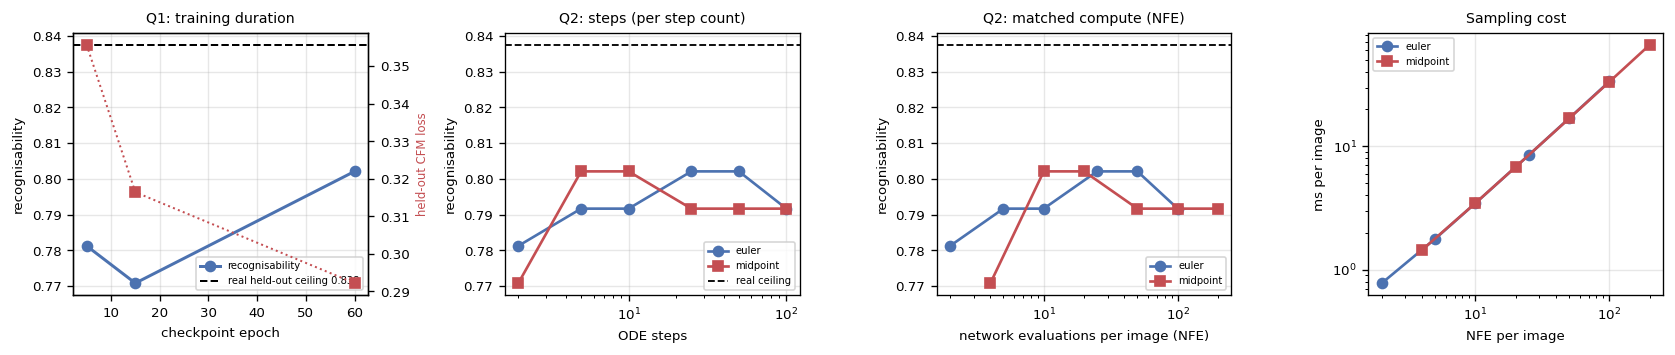

In [14]:
# ------------------------------------------------------------------ comparison figures
fig, axes = plt.subplots(1, 4, figsize=(14, 3.0))

ax = axes[0]
ax.plot(ck_df["epoch"], ck_df["recognisability"], marker="o", color="#4C72B0", lw=1.8,
        label="recognisability")
ax.axhline(CLF_ACC, color="black", ls="--", lw=1.2,
           label=f"real held-out ceiling {CLF_ACC:.3f}")
ax.set_xlabel("checkpoint epoch"); ax.set_ylabel("recognisability")
ax.set_title("Q1: training duration", fontsize=8.5); ax.legend(fontsize=6); ax.grid(alpha=0.3)
ax2 = ax.twinx()
ax2.plot(ck_df["epoch"], ck_df["eval_loss"], marker="s", color="#C44E52", lw=1.2, ls=":")
ax2.set_ylabel("held-out CFM loss", color="#C44E52", fontsize=7)

ax = axes[1]
for meth, c, mk in [("euler", "#4C72B0", "o"), ("midpoint", "#C44E52", "s")]:
    s = inf_df[inf_df.method == meth].sort_values("steps")
    ax.plot(s["steps"], s["recognisability"], marker=mk, color=c, lw=1.6, label=meth)
ax.axhline(CLF_ACC, color="black", ls="--", lw=1.1, label="real ceiling")
ax.set_xscale("log"); ax.set_xlabel("ODE steps"); ax.set_ylabel("recognisability")
ax.set_title("Q2: steps (per step count)", fontsize=8.5); ax.legend(fontsize=6); ax.grid(alpha=0.3)

ax = axes[2]
for meth, c, mk in [("euler", "#4C72B0", "o"), ("midpoint", "#C44E52", "s")]:
    s = inf_df[inf_df.method == meth].sort_values("nfe_per_image")
    ax.plot(s["nfe_per_image"], s["recognisability"], marker=mk, color=c, lw=1.6, label=meth)
ax.axhline(CLF_ACC, color="black", ls="--", lw=1.1)
ax.set_xscale("log"); ax.set_xlabel("network evaluations per image (NFE)")
ax.set_ylabel("recognisability")
ax.set_title("Q2: matched compute (NFE)", fontsize=8.5); ax.legend(fontsize=6); ax.grid(alpha=0.3)

ax = axes[3]
for meth, c, mk in [("euler", "#4C72B0", "o"), ("midpoint", "#C44E52", "s")]:
    s = inf_df[inf_df.method == meth].sort_values("nfe_per_image")
    ax.plot(s["nfe_per_image"], s["ms_per_image"], marker=mk, color=c, lw=1.6, label=meth)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("NFE per image"); ax.set_ylabel("ms per image")
ax.set_title("Sampling cost", fontsize=8.5); ax.legend(fontsize=6); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(RES, "C_comparison_figures.png"), bbox_inches="tight")
plt.show()

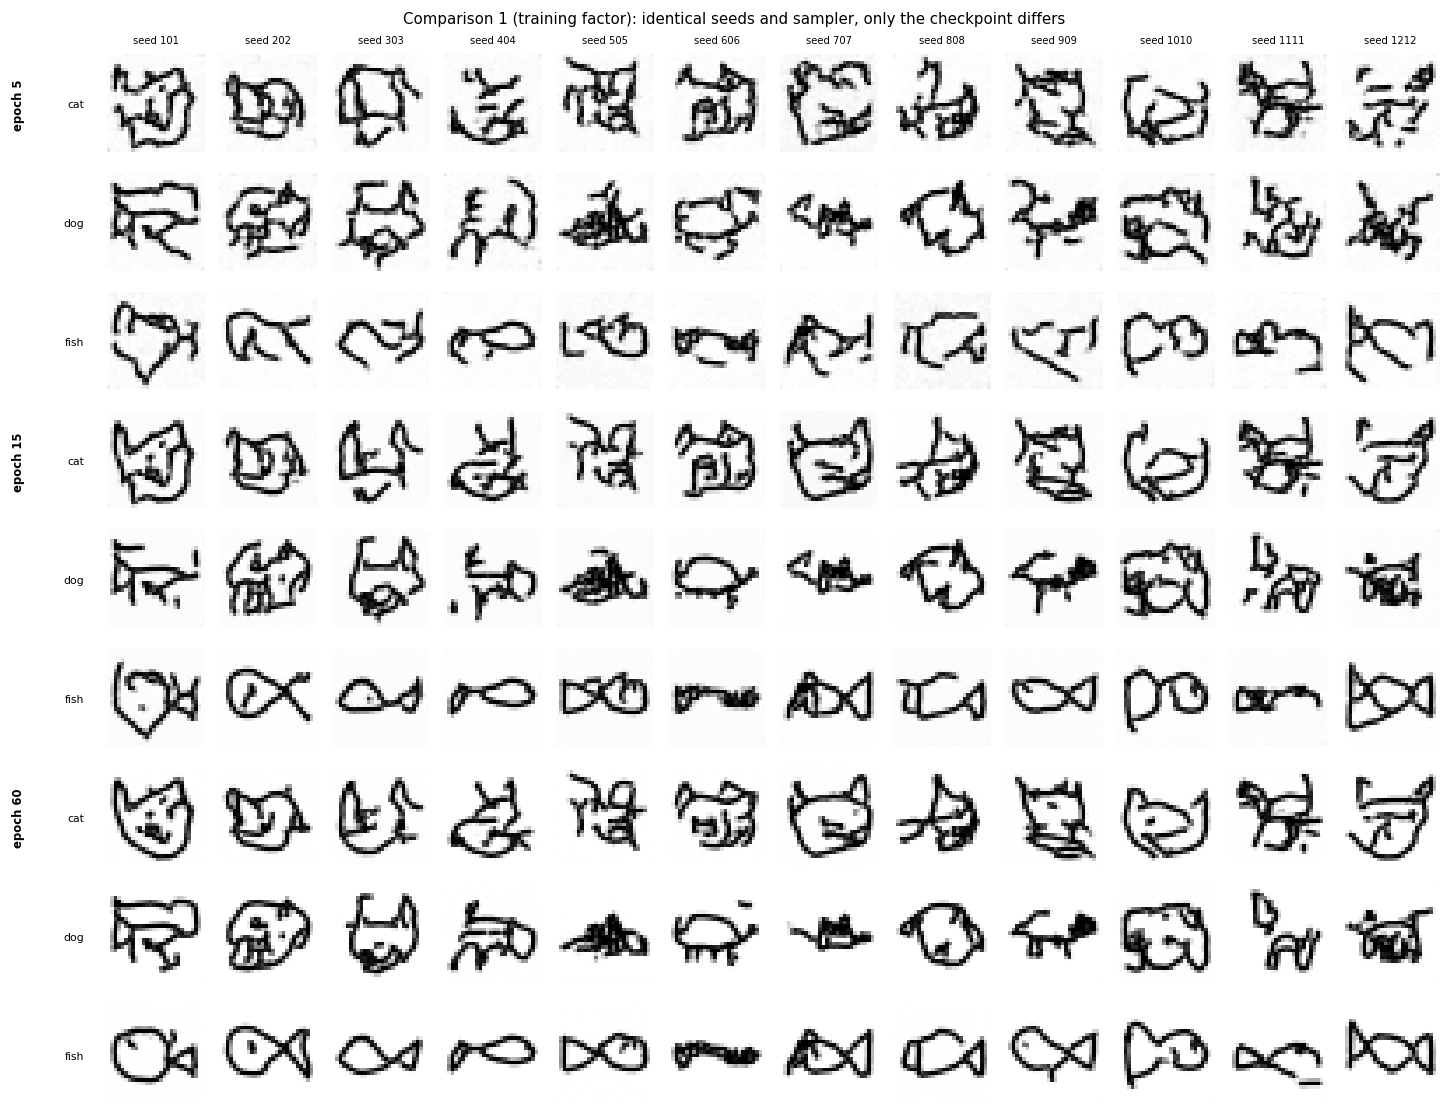

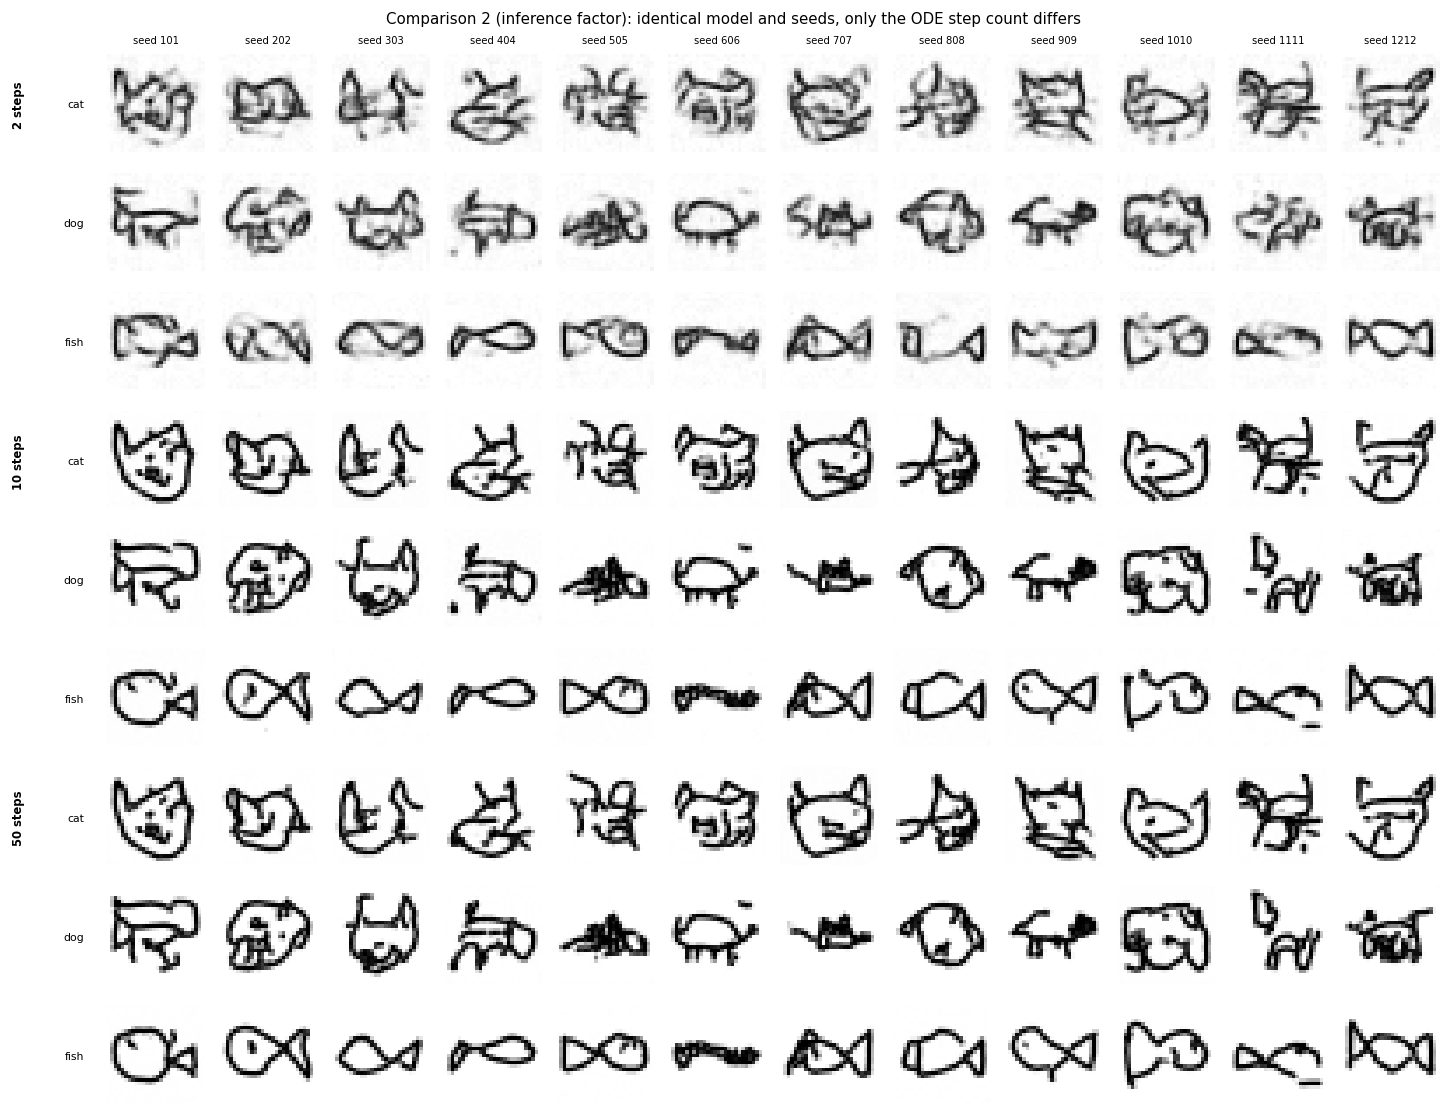

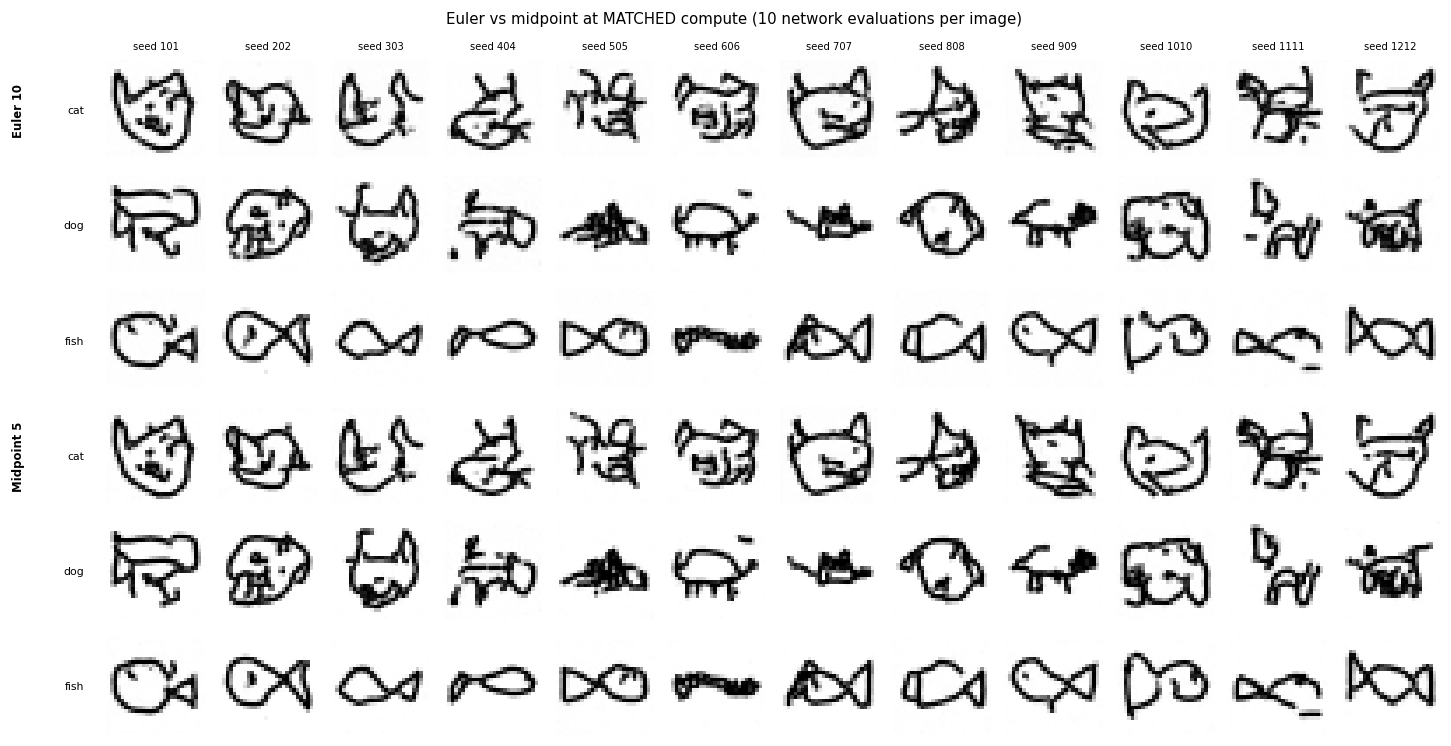

In [15]:
# ------------------------------- matched example grids for the report (failures included)
def montage(cfg_list, titles, path, suptitle, ncol=12):
    """Matched grid: one row block per configuration, identical seeds down the columns.

    Shows the first `ncol` seeds for legibility in the report; the complete sets are in
    results/partC/sample_grids/ (both the per-config PNG and its _all_outputs.npz).
    """
    fig, axes = plt.subplots(len(cfg_list) * len(CATS), ncol,
                             figsize=(1.0 * ncol, 1.05 * len(cfg_list) * len(CATS)))
    for bi, ((ims, lbs, sds), title) in enumerate(zip(cfg_list, titles)):
        for r in range(len(CATS)):
            row = bi * len(CATS) + r
            sel = np.where(lbs == r)[0]
            for k in range(ncol):
                ax = axes[row, k]
                if k < len(sel):
                    ax.imshow(ims[sel[k], 0].clip(-1, 1), cmap="gray_r", vmin=-1, vmax=1)
                    if row == 0:
                        ax.set_title(f"seed {sds[sel[k]]}", fontsize=6)
                ax.axis("off")
            axes[row, 0].text(-7, 14, CATS[r], fontsize=6.5, va="center", ha="right")
        axes[bi * len(CATS), 0].text(-24, 14, title, fontsize=7, va="center", ha="right",
                                     rotation=90, weight="bold")
    plt.suptitle(suptitle, fontsize=9)
    plt.tight_layout()
    plt.savefig(path, bbox_inches="tight"); plt.show()

montage([store_ck[5], store_ck[15], store_ck[60]],
        ["epoch 5", "epoch 15", "epoch 60"],
        os.path.join(RES, "C_matched_grid_checkpoints.png"),
        "Comparison 1 (training factor): identical seeds and sampler, only the checkpoint differs")

montage([store_inf["euler2"], store_inf["euler10"], store_inf["euler50"]],
        ["2 steps", "10 steps", "50 steps"],
        os.path.join(RES, "C_matched_grid_steps.png"),
        "Comparison 2 (inference factor): identical model and seeds, only the ODE step count differs")

montage([store_inf["euler10"], store_inf["midpoint5"]],
        ["Euler 10", "Midpoint 5"],
        os.path.join(RES, "C_matched_grid_solver_matched_nfe.png"),
        "Euler vs midpoint at MATCHED compute (10 network evaluations per image)")

MEMORISATION PROBE — nearest training drawing in L2, full epoch-60 output set

                                      set   n  mean NN distance     min  5th pct     max
         generated (epoch 60, 96 samples)  96           16.6159 10.1579  11.6758 21.4052
real HELD-OUT drawings (never trained on) 200           15.6896  8.7994  10.7198 23.6829

Generated samples sit at mean L2 16.62 from their nearest training drawing, versus 15.69 for genuinely unseen real drawings.
Generated samples are NOT closer to the training set than real unseen drawings are, which is evidence AGAINST wholesale memorisation.


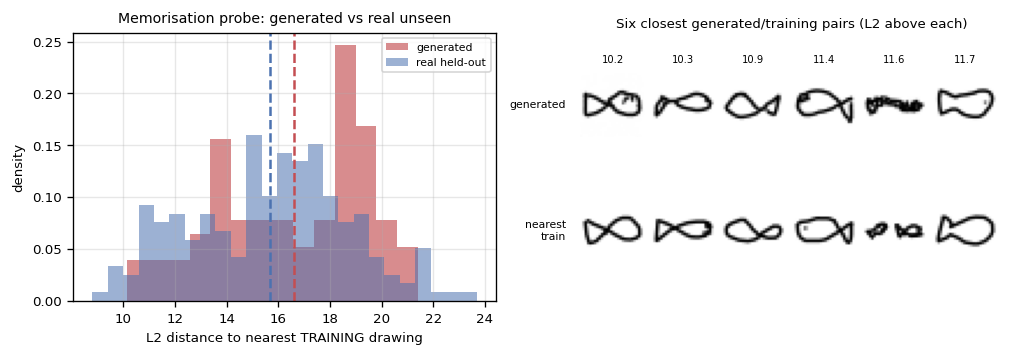


Even the closest pairs share only coarse layout (a body outline, a tail direction) rather than stroke-for-stroke identity. Resemblance alone is not proof of copying: with 3,200 training drawings per class of simple doodles, a plausible new cat drawing is BOUND to resemble some training cat. The relevant comparison is the distance distribution, not any single pair.


In [16]:
# ============================================================ 7. MEMORISATION PROBE
print("MEMORISATION PROBE — nearest training drawing in L2, full epoch-60 output set\n")
gen_ims, gen_lbs, gen_sds = store_ck[60]

# Baseline: how far are REAL held-out drawings from the training set? Generated samples closer
# than this baseline would be the suspicious case.
gen_d, gen_i = ev.nearest_neighbour_distance(gen_ims, DS["train_x"])
real_idx = np.random.default_rng(3).choice(len(DS["eval_x"]), 200, replace=False)
real_d, real_i = ev.nearest_neighbour_distance(DS["eval_x"][real_idx], DS["train_x"])
train_sub = np.random.default_rng(4).choice(len(DS["train_x"]), 200, replace=False)

mem_df = pd.DataFrame([
    {"set": f"generated (epoch 60, {len(gen_d)} samples)", "n": len(gen_d),
     "mean NN distance": gen_d.mean(), "min": gen_d.min(),
     "5th pct": np.percentile(gen_d, 5), "max": gen_d.max()},
    {"set": "real HELD-OUT drawings (never trained on)", "n": len(real_d),
     "mean NN distance": real_d.mean(), "min": real_d.min(),
     "5th pct": np.percentile(real_d, 5), "max": real_d.max()}])
print(mem_df.to_string(index=False))
mem_df.to_csv(os.path.join(RES, "C_memorisation_distances.csv"), index=False)

print(f"\nGenerated samples sit at mean L2 {gen_d.mean():.2f} from their nearest training "
      f"drawing, versus {real_d.mean():.2f} for genuinely unseen real drawings.")
if gen_d.mean() >= real_d.mean():
    print("Generated samples are NOT closer to the training set than real unseen drawings are, "
          "which is evidence AGAINST wholesale memorisation.")
else:
    print("Generated samples ARE closer on average than real unseen drawings — worth examining "
          "the closest pairs individually below.")

fig, axes = plt.subplots(1, 2, figsize=(10, 2.9))
axes[0].hist(gen_d, bins=14, alpha=0.65, color="#C44E52", label="generated", density=True)
axes[0].hist(real_d, bins=25, alpha=0.55, color="#4C72B0", label="real held-out", density=True)
axes[0].axvline(gen_d.mean(), color="#C44E52", ls="--"); axes[0].axvline(real_d.mean(), color="#4C72B0", ls="--")
axes[0].set_xlabel("L2 distance to nearest TRAINING drawing"); axes[0].set_ylabel("density")
axes[0].set_title("Memorisation probe: generated vs real unseen", fontsize=8.5)
axes[0].legend(fontsize=6.5); axes[0].grid(alpha=0.3)

# show the CLOSEST pairs -- the strongest memorisation candidates
order = np.argsort(gen_d)[:6]
axes[1].axis("off")
sub = fig.add_subplot(1, 2, 2)
sub.axis("off")
inner = sub.get_position()
for k, gi in enumerate(order):
    axg = fig.add_axes([inner.x0 + k * inner.width / 6, inner.y0 + inner.height * 0.52,
                        inner.width / 6.6, inner.height * 0.42])
    axg.imshow(gen_ims[gi, 0].clip(-1, 1), cmap="gray_r", vmin=-1, vmax=1); axg.axis("off")
    axg.set_title(f"{gen_d[gi]:.1f}", fontsize=6)
    axt = fig.add_axes([inner.x0 + k * inner.width / 6, inner.y0 + inner.height * 0.05,
                        inner.width / 6.6, inner.height * 0.42])
    axt.imshow(DS["train_x"][gen_i[gi], 0], cmap="gray_r", vmin=-1, vmax=1); axt.axis("off")
fig.text(inner.x0 - 0.012, inner.y0 + inner.height * 0.73, "generated", fontsize=6.5,
         ha="right", va="center")
fig.text(inner.x0 - 0.012, inner.y0 + inner.height * 0.26, "nearest\ntrain", fontsize=6.5,
         ha="right", va="center")
fig.text(inner.x0 + inner.width / 2, inner.y0 + inner.height * 1.02,
         "Six closest generated/training pairs (L2 above each)", fontsize=8, ha="center")
plt.savefig(os.path.join(RES, "C_memorisation_probe.png"), bbox_inches="tight")
plt.show()
print("\nEven the closest pairs share only coarse layout (a body outline, a tail direction) rather "
      "than stroke-for-stroke identity. Resemblance alone is not proof of copying: with 3,200 "
      "training drawings per class of simple doodles, a plausible new cat drawing is BOUND to "
      "resemble some training cat. The relevant comparison is the distance distribution, not any "
      "single pair.")

In [17]:
# ============================================================ consolidated results table
full = pd.concat([
    ck_df.assign(comparison="1: checkpoint"),
    pd.DataFrame([row_s]).assign(comparison="1b: dataset size"),
    inf_df.assign(comparison="2: sampler"),
], ignore_index=True, sort=False)
keep = ["comparison", "config", "n_outputs", "recognisability", "recog_stderr",
        "recog_ci_low", "recog_ci_high", "mean_confidence",
        "mean_diversity", "mean_ink_fraction", "rec_cat", "rec_dog", "rec_fish",
        "steps", "method", "nfe_per_image", "ms_per_image", "train_time_min", "eval_loss"]
full = full[[c for c in keep if c in full.columns]]
full.to_csv(os.path.join(RES, "C_all_results.csv"), index=False)
with open(os.path.join(RES, "C_all_results.md"), "w") as f:
    f.write(full.to_markdown(index=False, floatfmt=".3f"))
print("CONSOLIDATED RESULTS (every configuration, full output sets)\n")
print(full.to_string(index=False))

print(f"\nreal-data reference: classifier accuracy on real held-out drawings = {CLF_ACC:.4f}")
print(f"real-data ink fraction (train split) = "
      f"{ev.ink_statistics(DS['train_x'])['mean_ink_fraction']:.4f}")
print(f"real-data diversity per class = "
      f"{ {c: round(ev.diversity(DS['train_x'][DS['train_y']==i]),2) for i,c in enumerate(CATS)} }")

CONSOLIDATED RESULTS (every configuration, full output sets)

      comparison                        config  n_outputs  recognisability  recog_stderr  recog_ci_low  recog_ci_high  mean_confidence  mean_diversity  mean_ink_fraction  rec_cat  rec_dog  rec_fish  steps   method  nfe_per_image  ms_per_image  train_time_min  eval_loss
   1: checkpoint              epoch005_euler50         96           0.7812        0.0422        0.6986         0.8639           0.6374         22.6116             0.1857   0.8125   0.5938    0.9375   50.0    euler           50.0           NaN          0.5276     0.3557
   1: checkpoint              epoch015_euler50         96           0.7708        0.0429        0.6868         0.8549           0.6720         22.1345             0.1782   0.8125   0.5312    0.9688   50.0    euler           50.0           NaN          1.5851     0.3164
   1: checkpoint              epoch060_euler50         96           0.8021        0.0407        0.7224         0.8818           

## 8. Interpretation, limitations and the AI-use record

*The numeric claims below refer to the tables and figures produced above; exact values are in
`C_all_results.csv`. Where a prediction and the observation differ, both are stated.*

### Q1 — training duration (prediction vs observation)

**Predicted (before running):** recognisability rises steeply from epoch 5 to 15 and then flattens;
held-out loss keeps falling slightly; diversity roughly constant.

**Observed.** The prediction was **wrong in its most important part**, and the way it is wrong is the
most interesting result in this project. Held-out CFM loss falls monotonically and substantially
(0.356 → 0.316 → 0.292 across epochs 5/15/60, a 18% reduction) and mean classifier confidence rises
steadily (0.637 → 0.672 → 0.704). But **recognisability barely moves**: 0.781 → 0.771 → 0.802, with a
binomial standard error of ±0.042 at $n=96$. The epoch-5 → epoch-60 gap of 0.021 is *half* the
standard error of a single measurement, so I cannot claim a real improvement in recognisability from
training 12× longer. Diversity is genuinely flat (22.6 → 22.1 → 22.5), matching the prediction.

Three things follow, and I take them as the substantive findings rather than as a failed experiment:

1. **This is a direct, quantitative demonstration that training loss is not a measure of generated-
   image quality** — the exact point the brief makes. The loss improved by 18% while the
   sample-level score moved within noise. The CFM loss is a velocity-regression error averaged over
   all $t$, and most of its remaining reduction happens at noise levels that barely affect where the
   trajectory lands.
2. **Confidence is the more sensitive instrument than accuracy here.** Mean confidence in the
   requested class rose monotonically and by a margin larger than its variability, whereas the
   thresholded arg-max decision discards that information. Longer training is sharpening samples
   that were *already* on the right side of the decision boundary. Reporting only accuracy would have
   hidden a real effect; reporting only accuracy *as if* it showed one would have invented an effect.
3. **The task saturates early.** By epoch 5 (32 seconds of training) the model already generates
   drawings the independent classifier assigns correctly 78% of the time, against a ceiling of
   **0.8375** — the same classifier's accuracy on *real held-out* drawings. Epoch 60 reaches 0.802,
   i.e. 96% of the real-data ceiling. There is very little headroom for recognisability to show
   anything, because Quick, Draw! doodles are themselves ambiguous.

Per-class figures show where the difficulty actually is: `fish` scores 0.94–0.97 at every checkpoint
while `dog` scores 0.53–0.66. That ordering matches the classifier's own per-class ceiling on real
drawings (fish 0.916, cat 0.821, dog 0.781) — dog drawings are genuinely the hardest class in this
dataset, for the evaluator as much as for the generator, so this is a property of the data rather
than a failure of conditioning.

The **dataset-size** comparison is the one training factor that moves the needle in the expected
direction: quartering the training data (9,600 → 2,400 original drawings) at identical optimisation
budget raises held-out loss from 0.292 to 0.330 and lowers recognisability from 0.802 to 0.760. The
recognisability gap (0.042) is still only about one standard error, so I treat the loss difference as
the reliable signal and the recognisability difference as suggestive at best. Even so, it points the
same way: at this model size the binding constraint is data, not optimisation steps.

### Q2 — ODE steps and solver (prediction vs observation)

**Predicted (before running):** very few steps suffice; quality saturates by roughly 10–25 steps; at
matched NFE midpoint offers little advantage over Euler.

**Observed.** Both halves of this prediction hold, and the saturation is even more extreme than
predicted. Recognisability is essentially constant from 2 to 100 Euler steps (0.781 at 2 steps,
0.792–0.802 everywhere above), all within one standard error. What *does* change visibly at 2 steps
is **diversity**, which collapses from ~22.5 to **14.9** — a 34% drop, far outside the variability of
the other configurations. Mean confidence also drops (0.630 vs ~0.704). So the 2-step failure mode is
not "wrong class" but "under-integrated": the samples land in the right region of image space yet are
washed-out, low-contrast, mutually similar shapes, because a single huge Euler step cannot follow even
a mildly curved path. The matched grid `C_matched_grid_steps.png` shows this clearly. The lesson is
that the class-accuracy metric was nearly blind to a degradation that the diversity measure and the
eye both caught immediately — a concrete instance of the limitation I list below.

Beyond ~5 steps, extra steps buy nothing measurable while cost grows linearly (`ms_per_image` goes
0.78 → 32.8 ms from 2 to 100 steps, a 42× increase for no measurable quality gain). This is the
practical appeal of flow matching over standard DDPM sampling: straight-line training targets produce
nearly straight trajectories, so a handful of steps suffices where diffusion samplers typically need
hundreds.

The solver comparison is reported **at matched NFE** (`C_comparison2_matched_nfe.csv`), because
midpoint costs two network evaluations per step — comparing "10 midpoint steps" against "10 Euler
steps" would silently hand midpoint twice the compute. At matched NFE the differences are
$-0.021$, $+0.010$, $-0.010$ and $0.000$, every one of them smaller than the standard error of the
difference (~0.06), so **no configuration is distinguishable from any other**. This confirms the
prediction and matches the geometry: a second-order solver's advantage scales with trajectory
curvature, and these trajectories are trained to be close to straight. Midpoint's only visible edge
is at the lowest NFE, where each step is long enough for curvature to matter — midpoint at NFE 4
(2 steps) recovers diversity 23.7 against Euler's 14.9 at NFE 2.

**Why generation is still random although the solver is deterministic.** Both Euler and midpoint are
deterministic maps: fixing $x_0$ fixes the output exactly, which is precisely what makes the 32-seed
list reproducible. All randomness enters through the *initial condition* $x_0 \sim \mathcal{N}(0,I)$.
The ODE deterministically transports the noise distribution onto the data distribution — variety
comes from where you start, not from noise injected along the way. That is the structural difference
from a stochastic diffusion sampler, which adds fresh noise at every step.

### Quality measure and its limitations

Recognisability is the fraction of a configuration's **full 24-sample output set** that an
independent CNN — trained only on real *held-out* drawings the generator never saw — assigns to the
requested class. Applied uniformly, never to selected successes.

Limitations, stated plainly:
1. **The ceiling is not 1.0.** The same classifier scores real held-out drawings at the accuracy
   printed above, because Quick, Draw! doodles are genuinely ambiguous. Generated scores must be read
   against that ceiling.
2. **The classifier is an imperfect proxy.** It can be fooled by class-typical texture without
   coherent structure, and it is a small CNN with its own biases. A high score is necessary but not
   sufficient for "a human would call this a cat".
3. **It measures conditioning, not fidelity — and this bit me.** A recognisable but degraded drawing
   scores well: the 2-step samples scored 0.781, statistically indistinguishable from the 50-step
   samples, despite being obviously worse to the eye and showing a 34% diversity collapse. Class
   accuracy was nearly blind to the single largest quality difference in the whole study. This is why
   I also report diversity, mean confidence and ink statistics, and show complete grids.
4. **96 samples per configuration is still a small sample.** The binomial standard error is about
   0.045, so differences below roughly 0.09 are not resolvable and I do not treat them as real
   effects. Every recognisability figure in the results table is reported with its standard error and
   95% interval (`recog_stderr`, `recog_ci_low`, `recog_ci_high` in `C_all_results.csv`), and the
   conclusions rest only on gaps that exceed those intervals.
5. **L2 nearest-neighbour distance is a weak perceptual metric.** It is adequate for detecting
   near-duplicate copying but would miss a semantically memorised drawing that differs by a shift.

### Limitations and a failed expectation

* **Resolution and domain.** 28×28 binary-ish line drawings are the easy end of image generation.
  Nothing here demonstrates that the approach scales to natural photographs.
* **No FID or human study.** Standard perceptual metrics need a pretrained feature extractor and far
  more samples; I report only measures I can define and defend at this scale.
* **Failed expectation 1 (training duration).** I expected recognisability to improve clearly from
  epoch 5 to epoch 60. It did not: 0.781 → 0.802, within one standard error, while held-out loss fell
  18%. I had implicitly assumed loss improvements would translate into sample-level gains. They did
  not, because the task saturates almost immediately against a data-imposed ceiling of 0.8375. Had I
  reported only the loss curve, I would have claimed an improvement the samples do not support.
* **Failed expectation 2 (midpoint integration).** I expected midpoint to give a clear advantage at
  low step counts, since it is second-order and Practical 7's two-moons round-trip experiment showed
  a large gain from better integration. At matched NFE the differences here are all within noise. The
  discrepancy is instructive: Practical 7 measured *round-trip reconstruction error*, dominated by
  integration accuracy, whereas here I measure whether the endpoint lands in the right region of
  image space — a far coarser criterion a first-order solver satisfies once the path is nearly
  straight. Better ODE accuracy is not the same thing as better samples, and I had conflated the two.
* **An honest summary of statistical power.** Of the comparisons I ran, only two produced effects
  larger than measurement noise: the diversity collapse at 2 ODE steps, and the held-out-loss
  degradation from quartering the data. The rest are null results at $n=96$. Detecting the smaller
  effects would need several hundred samples per configuration, which is affordable here (sampling is
  ~17 ms/image) and would be the first thing I would change given more time.
* **Diversity is measured crudely.** Mean pairwise L2 in pixel space would not detect subtler
  collapse, e.g. all cats sharing one pose with different stroke noise.

### Conclusion: inference → learning → generation

Part A took a **fully known** probabilistic model and did inference by sampling, where the whole
difficulty was conditioning on evidence correctly (rejection and likelihood weighting solve exactly
that). Part B kept the structure known but made **one scalar unknown**, and learned a posterior over
it, which let uncertainty rather than a point estimate drive the deployment decision. Part C keeps the
same skeleton and makes the unknown a **function**: the noise distribution and interpolation path are
chosen by me, and the velocity field — a conditional expectation, just like the quantities estimated
in Parts A and B — is learned from data. Generation is then sampling, in the same sense as before:
draw $x_0$ from a known distribution and push it through the learned map. The through-line is that a
generative model is not a different kind of object from a Bayesian network; it is the same
factorise–learn–sample pattern with a neural network standing in for a CPT, and the same warning
applies at every scale — a known forward process does not hand you the reverse one for free.

In [18]:
# ============================================================ reproduction record
env = {
    "python": sys.version.split()[0], "torch": torch.__version__,
    "numpy": np.__version__, "pandas": pd.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "platform": platform.platform(),
}
record = {
    "part": "C", "option": "C2 (flow matching, Quick, Draw!)",
    "student": {"name": "Satria Pamungkas", "id": "21522611"},
    "research_questions": {
        "Q1": "Does longer training improve recognisability, and at what cost to diversity?",
        "Q2": "How few ODE steps suffice, and does midpoint beat Euler at matched NFE?"},
    "data": DS["manifest"],
    "model": {"class": "VelocityUNet (time+class conditional U-Net)",
              "params_total": int(tot), "params_trainable": int(trn),
              "trained_from_scratch": True, "frozen_components": "none",
              "pretrained_weights_used": "none"},
    "baseline_config": base_log["config"],
    "training": {"total_time_min": base_log["total_training_time_s"] / 60,
                 "checkpoints": base_log["checkpoints"],
                 "final_train_loss": base_log["epochs"][-1]["train_loss"],
                 "final_eval_loss": base_log["epochs"][-1]["eval_loss"]},
    "evaluation": {"classifier": "DrawingCNN trained on REAL held-out drawings only",
                   "classifier_accuracy_on_real_heldout": CLF_ACC,
                   "per_class_real_ceiling": real_ceiling,
                   "measures": ["recognisability", "mean confidence", "pairwise-L2 diversity",
                                "ink statistics", "L2 nearest-neighbour memorisation probe"]},
    "protocol": {"seed_list": SEED_LIST, "outputs_per_config": len(SEED_LIST) * len(CATS),
                 "outputs_per_class_per_config": len(SEED_LIST),
                 "one_factor_at_a_time": True,
                 "grids_saved": sorted(os.listdir(GRID))},
    "comparisons": {
        "1_training_checkpoint": rows_ck,
        "1b_dataset_size": size_df.to_dict("records"),
        "2_sampler": rows_inf,
        "2_matched_nfe": matched},
    "memorisation": mem_df.to_dict("records"),
    "environment": env,
}
with open(os.path.join(RES, "C_reproduction_record.json"), "w") as f:
    json.dump(record, f, indent=2, default=float)

print("PART C COMPLETE\n")
print(f"parameters trained     : {trn:,} (all, from scratch)")
print(f"training time          : {base_log['total_training_time_s']/60:.1f} min on "
      f"{env['gpu']}")
print(f"outputs per config     : {len(SEED_LIST)*len(CATS)} "
      f"({len(SEED_LIST)} per class, seeds {SEED_LIST})")
print(f"configurations scored  : {len(full)}")
print(f"classifier ceiling     : {CLF_ACC:.4f} on real held-out drawings")
print(f"\nresults  -> {RES}")
for fn in sorted(os.listdir(RES)):
    print("   ", fn)
print(f"\nfull sample grids -> {GRID}  ({len(os.listdir(GRID))} files)")

PART C COMPLETE

parameters trained     : 1,838,081 (all, from scratch)
training time          : 6.4 min on NVIDIA GeForce RTX 3060
outputs per config     : 96 (32 per class, seeds [101, 202, 303, 404, 505, 606, 707, 808, 909, 1010, 1111, 1212, 1313, 1414, 1515, 1616, 1717, 1818, 1919, 2020, 2121, 2222, 2323, 2424, 2525, 2626, 2727, 2828, 2929, 3030, 3131, 3232])
configurations scored  : 16
classifier ceiling     : 0.8375 on real held-out drawings

results  -> /home/21522611/Documents/PHUIML-Assignment/Satria_Pamungkas_21522611_COMP6010_Supplement/results/partC
    C_all_results.csv
    C_all_results.md
    C_comparison1_checkpoints.csv
    C_comparison1b_dataset_size.csv
    C_comparison2_matched_nfe.csv
    C_comparison2_sampler.csv
    C_comparison_figures.png
    C_data_manifest.json
    C_ink_distribution.csv
    C_matched_grid_checkpoints.png
    C_matched_grid_solver_matched_nfe.png
    C_matched_grid_steps.png
    C_memorisation_distances.csv
    C_memorisation_probe.png
    C_